# Микробиом кишечника и колоректальный рак
Локальный исследовательский ноутбук для задачи Genotek × ЦУ. Для запуска нужны Python 3, NumPy, pandas, SciPy, scikit-learn, CatBoost, LightGBM и Matplotlib. Укажите пути к двум CSV в первой ячейке. Код читает эти два CSV и сохраняет `submission.csv` с оценками класса КРР. В слайдах организаторов применение ИИ ограничено поиском литературы, визуализациями и оформлением слайдов. Допустимость использования этого исследовательского кода для официальной сдачи требует подтверждения организаторов.

In [1]:
import os
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import scipy
import sklearn
import catboost
import lightgbm
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from IPython.display import Markdown, display
from scipy.stats import rankdata, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold, LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
TRAIN_PATH = Path(os.environ.get("GUT_TRAIN", "train.csv"))
TEST_PATH = Path(os.environ.get("GUT_TEST", "test.csv"))
EPS = 1e-5
COVARIATES = ["age", "gender", "bmi", "library_size"]

for name, module in [
    ("NumPy", np), ("pandas", pd), ("SciPy", scipy),
    ("scikit-learn", sklearn), ("CatBoost", catboost), ("LightGBM", lightgbm)
]:
    print(f"{name} {module.__version__}")

NumPy 1.26.4
pandas 2.3.2
SciPy 1.13.1
scikit-learn 1.7.2
CatBoost 1.2.10
LightGBM 4.6.0


## 1. Данные и гипотезы
Метки и единицы сверены с [описанием данных](https://stackmorelayers.ai/competitions/gutmicrobio/data) и [техническими требованиями](https://docs.google.com/document/d/1CxyA6Bjsd3L4NRkVM3DvQxyXpfb_nhj3ZnOkvk6bOtI/edit). Исходный EDA выявил возрастной сдвиг, различия по глубине и когорте, много нулей и слабые скорректированные связи альфа-разнообразия с диагнозом. Сравнение train/test из EDA описательное. Рейтинги EDA не используются для отбора.

1. Если подвидовые доли дублируют диагностический сигнал, агрегация уменьшит число признаков при сопоставимой AUC.
2. Если обнаружение и численность несут разные сигналы, сравнение исходных долей, log1p, CLR, флагов и двухчастного кодирования это покажет.
3. Если оральные таксоны добавляют информацию, отдельные маркеры и их баланс с кишечными комменсалами улучшат AUC поверх отобранных таксонов.
4. Если разнообразие, глубина или возраст объясняют часть качества, это покажут абляции и отдельные модели метаданных. Когорта используется для разбиения и диагностического контроля, в итоговую модель она не поступает.
5. Проверяем, дают ли ранги оральной панели и отдельный mOTU animalis прирост при одинаковом алгоритме и наборе базовых признаков.

Train 415 × 856, mOTU 849. Нули 71.97%.
Сумма долей: медиана 0.9666, минимум 0.5681.
Богатство: медиана 238. Связь с глубиной (Спирмен) 0.286.
Повторные идентичные профили: 0. Неизменные таксоны: 0.
Доступен ID образца. ID пациента и партии отсутствуют.


,Пропуски
bmi,3


label,Контроль,КРР,Доля КРР
cohort,,,
AUS,48,31,0.392
CHI,41,58,0.586
FRA,43,37,0.462
GER,44,43,0.494
USA,34,36,0.514


age    bmi  library_size
cohort label                            
AUS    0      68.15  27.92   24805239.67
       1      68.29  27.00   27962522.84
CHI    0      61.32  23.34   22603564.20
       1      66.28  24.14   19118985.76
FRA    0      59.53  24.02   28661723.67
       1      67.49  25.94   28309027.08
GER    0      55.43  24.97   16842521.23
       1      63.21  26.66   30143694.74
USA    0      60.00  25.03   31264320.38
       1      60.44  24.41   33180143.47

label          Контроль  КРР
cohort gender               
AUS    F             19   11
       M             29   20
CHI    F             14   18
       M             27   40
FRA    F             24   16
       M             19   21
GER    F             21   15
       M             23   28
USA    F              5    7
       M             29   29

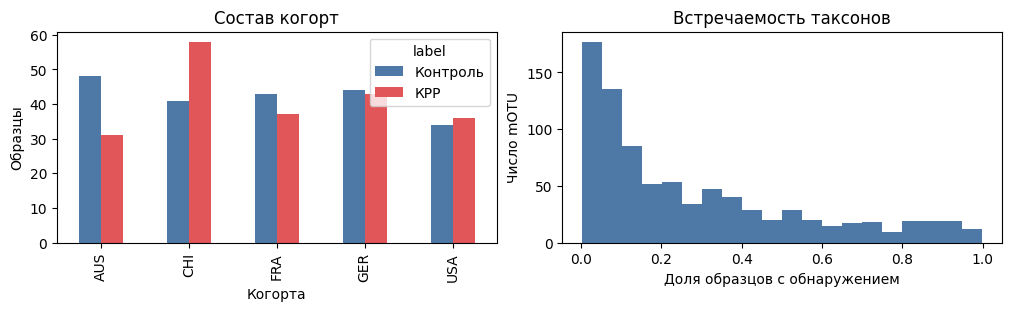

In [2]:
train = pd.read_csv(TRAIN_PATH, dtype={"sample_id": str})
assert train["sample_id"].notna().all() and train["sample_id"].is_unique
assert set(train["label"].unique()) == {0, 1}
train = train.sort_values("sample_id").reset_index(drop=True)
taxa = sorted(c for c in train if c.endswith("]") and "_mOTU_v2_" in c)
required = {"sample_id", "label", "cohort", *COVARIATES, *taxa}
assert set(train.columns) == required, "Проверьте состав столбцов train"
a = train[taxa].to_numpy()
assert np.isfinite(a).all() and ((0 <= a) & (a <= 1)).all()
y = train["label"].to_numpy()
cohort = train["cohort"].to_numpy()
profile_group = pd.util.hash_pandas_object(train[taxa], index=False).to_numpy()
coverage = a.sum(axis=1)
richness = (a > 0).sum(axis=1)
print(f"Train {train.shape[0]} × {train.shape[1]}, mOTU {len(taxa)}. Нули {(a == 0).mean():.2%}.")
print(f"Сумма долей: медиана {np.median(coverage):.4f}, минимум {coverage.min():.4f}.")
print(f"Богатство: медиана {np.median(richness):.0f}. "
      f"Связь с глубиной (Спирмен) {spearmanr(richness, train.library_size).statistic:.3f}.")
print(f"Повторные идентичные профили: {pd.Series(profile_group).duplicated().sum()}. "
      f"Неизменные таксоны: {(a.max(axis=0) == a.min(axis=0)).sum()}.")
print("Доступен ID образца. ID пациента и партии отсутствуют.")
display(train.isna().sum().loc[lambda s: s > 0].rename("Пропуски").to_frame())
cohort_counts = pd.crosstab(train.cohort, train.label).rename(columns={0:"Контроль", 1:"КРР"})
cohort_counts["Доля КРР"] = cohort_counts["КРР"] / cohort_counts.sum(axis=1)
display(cohort_counts.round(3))
display(train.groupby(["cohort", "label"], observed=True)[["age","bmi","library_size"]].mean().round(2))
display(pd.crosstab([train.cohort, train.gender], train.label).rename(columns={0:"Контроль",1:"КРР"}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
cohort_counts[["Контроль", "КРР"]].plot.bar(ax=axes[0], color=["#4e79a7", "#e15759"])
axes[0].set(xlabel="Когорта", ylabel="Образцы", title="Состав когорт")
axes[1].hist((a > 0).mean(axis=0), bins=20, color="#4e79a7")
axes[1].set(xlabel="Доля образцов с обнаружением", ylabel="Число mOTU", title="Встречаемость таксонов")
plt.show()

## 2. Разбиение
Один из пяти стратифицированных сгибов по сочетанию «когорта × класс» отведён под holdout. В оставшейся части используются общие 5 сгибов CV и пять LOCO-проверок. Повторные идентичные профили группируются, а повторные образцы одного пациента с разными профилями неидентифицируемы. Модели, предобработка, порог и выбор конфигурации используют только разработочную часть. Исходный EDA видел весь train, поэтому holdout не является внешней проверкой предварительных гипотез.

In [3]:
def mixed_splits(index):
    strata = np.char.add(np.char.add(cohort[index].astype(str), ":"), y[index].astype(str))
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    return [(index[i], index[j]) for i,j in splitter.split(index, strata, profile_group[index])]

dev, hold = mixed_splits(np.arange(len(train)))[0]
cv_splits = mixed_splits(dev)
loco_splits = [(dev[i], dev[j]) for i,j in LeaveOneGroupOut().split(dev, y[dev], cohort[dev])]
for i,j in [(dev, hold), *cv_splits, *loco_splits]:
    assert not np.intersect1d(i,j).size
    assert not np.intersect1d(profile_group[i],profile_group[j]).size
    assert len(np.unique(y[j])) == 2

def describe_split(name, index):
    return {"Часть": name, "N": len(index), "Доля train": len(index)/len(train),
            "Контроль": int((y[index] == 0).sum()), "КРР": int((y[index] == 1).sum())}

display(pd.DataFrame([describe_split("Разработка", dev), describe_split("Holdout", hold)]).round(4))
print("Исключено 0 образцов.")

,Часть,N,Доля train,Контроль,КРР
0,Разработка,332,0.8,168,164
1,Holdout,83,0.2,42,41


Исключено 0 образцов.


## 3. Признаки и научная опора
[Wirbel 2019](https://pmc.ncbi.nlm.nih.gov/articles/PMC7984229/), [Thomas 2019](https://pmc.ncbi.nlm.nih.gov/articles/PMC9533319/) и [Piccinno 2025](https://www.nature.com/articles/s41591-025-03693-9.pdf) мотивируют панель оральных таксонов. [Pekel 2026](https://www.embl.org/news/science-technology/large-scale-microbiome-study-identifies-robust-colorectal-cancer-signature/) поддерживает проверку родовых агрегатов. [mOTUs2](https://doi.org/10.1038/s41467-019-08844-4) и [Morton 2019](https://pmc.ncbi.nlm.nih.gov/articles/PMC6586903/) объясняют раздельные mOTU и композиционные отношения. Совпадение исходных когорт с публикациями возможно. Внешняя независимость панели здесь не установлена.

Оральные ранги характеризуют место панели среди обнаруженных таксонов пробы. Внутривидовую неоднородность Fusobacterium проверяем по отдельной колонке animalis. Этим mOTU набор не разрешает клады C1/C2. [Zepeda-Rivera et al., Nature, 2024](https://www.nature.com/articles/s41586-024-07182-w).

In [4]:
def taxon_name(column):
    return column.rsplit(" [", 1)[0]

def genus_name(column):
    words = taxon_name(column).removeprefix("unknown ").split()
    genus = words[0]
    if genus in {"Bacteria", "Archaea", "unclassified", "Candidatus", "Bacilli", "Bacteroidia", "Clostridia", "Mollicutes", "Negativicutes", "Gammaproteobacteria", "Betaproteobacteria", "Alphaproteobacteria", "Actinobacteria", "Deltaproteobacteria", "Erysipelotrichia"} or genus.endswith(
        ("aceae", "ales", "etes", "ota")
    ):
        return None
    if not genus.isalpha() or not genus[0].isupper():
        return None
    return genus

# Названия в версии mOTUs2, без автоматического перевода в современную таксономию.
FAMILY_MEMBERS = {
    "Fusobacteriaceae": {"Fusobacterium"},
    "Prevotellaceae": {"Prevotella", "Paraprevotella", "Alloprevotella"},
    "Porphyromonadaceae": {"Porphyromonas"},
    "Lachnospiraceae": {"Roseburia", "Lachnospira", "Blautia", "Dorea"},
}

def group_name(column, level):
    original = taxon_name(column)
    genus = genus_name(column)
    if level == "species" and genus is not None and not original.startswith("unknown "):
        words = original.split()
        if len(words) >= 2 and words[1].isalpha() and words[1].islower() and words[1] not in {"sp", "spp", "bacterium"}:
            return "Вид · " + " ".join(words[:2])
    if level == "family":
        for family, members in FAMILY_MEMBERS.items():
            if genus in members or original.removeprefix("unknown ").split()[0] == family:
                return "Семейство · " + family
    if level in {"genus", "family"} and genus is not None:
        return "Род · " + genus
    return column

def aggregate(raw, level):
    keys = [group_name(c, level) for c in raw]
    # Каждый исходный mOTU попадает ровно в одну группу данного уровня.
    grouped = raw.T.groupby(keys, sort=True).sum().T
    if not np.allclose(raw.sum(axis=1), grouped.sum(axis=1)):
        raise ValueError("Агрегация изменила суммарную долю")
    return grouped

ORAL = [
    "Fusobacterium nucleatum", "Parvimonas micra", "Peptostreptococcus stomatis",
    "Gemella morbillorum", "Solobacterium moorei", "Peptostreptococcus anaerobius",
    "Porphyromonas asaccharolytica", "Porphyromonas somerae", "Porphyromonas uenonis",
    "Prevotella intermedia",
]
GUT = ["Faecalibacterium prausnitzii", "Roseburia intestinalis", "Roseburia hominis"]

def transform(frame, method):
    if method == "raw":
        return frame
    if method == "presence":
        return frame.gt(0).astype(float)
    logged = np.log1p(frame / EPS)
    if method == "clr":
        return logged.sub(logged.mean(axis=1), axis=0)
    if method == "hurdle":
        # Порог обнаружения задан нулём. Для обнаруженных отдельно кодируется log-доля.
        return pd.concat([frame.gt(0).astype(float).add_prefix("Обнаружение · "),
                          np.log(frame.clip(lower=EPS) / 1e-3).where(frame.gt(0), 0)
                            .add_prefix("Доля при обнаружении · ")], axis=1)
    return logged

def make_features(df):
    raw = df[taxa]
    spec = aggregate(raw, "species")
    genus = aggregate(raw, "genus")
    family = aggregate(raw, "family")
    oral = spec.reindex(columns=["Вид · "+s for s in ORAL], fill_value=0)
    gut = spec.reindex(columns=["Вид · "+s for s in GUT], fill_value=0)
    panel = pd.concat([oral, gut], axis=1)
    values = raw.to_numpy()
    total = values.sum(axis=1)
    relative = values / np.maximum(total[:, None], EPS)
    entropy = -(relative * np.log(np.maximum(relative, np.finfo(float).tiny))).sum(axis=1)
    n_taxa = (values > 0).sum(axis=1)
    ecological = pd.DataFrame({
        "Богатство": n_taxa,
        "Шеннон": entropy,
        "Симпсон": 1 - (relative ** 2).sum(axis=1),
        "Выравненность": entropy / np.log(np.maximum(n_taxa, 2)),
        "Доля 10 крупнейших": np.sort(relative, axis=1)[:, -10:].sum(axis=1),
        "Сумма наблюдаемых долей": total,
    }, index=df.index)
    balance = pd.DataFrame({
        "Баланс оральные / кишечные": np.log(oral + EPS).mean(axis=1) - np.log(gut + EPS).mean(axis=1),
        "Число обнаруженных оральных видов": oral.gt(0).sum(axis=1),
        "Суммарная оральная доля": np.log1p(oral.sum(axis=1) / EPS),
        "Суммарная доля кишечной панели": np.log1p(gut.sum(axis=1) / EPS),
    }, index=df.index)
    # Процентиль считается по обнаруженным группам каждого образца. Нулю соответствует 0.
    pct = spec.where(spec.gt(0)).rank(axis=1, pct=True).fillna(0)
    oral_pct = pct.reindex(columns=oral.columns, fill_value=0)
    gut_pct = pct.reindex(columns=gut.columns, fill_value=0)
    seen_oral = oral.gt(0).sum(axis=1)
    fusobacterium = oral["Вид · Fusobacterium nucleatum"]
    animalis_columns = [c for c in taxa if taxon_name(c) == "Fusobacterium nucleatum s. animalis"]
    animalis = raw[animalis_columns].sum(axis=1)
    signature = pd.DataFrame({
        "Средний ранг обнаруженных оральных": oral_pct.sum(axis=1) / seen_oral.clip(lower=1),
        "Оральная панель · таксонов в верхней четверти": oral_pct.ge(.75).sum(axis=1),
        "Контраст процентилей оральные / кишечные": oral_pct.mean(axis=1) - gut_pct.mean(axis=1),
        "Доля крупнейшего вида в оральной панели": oral.max(axis=1) / oral.sum(axis=1).clip(lower=EPS),
        "F. nucleatum animalis · log-доля": np.log1p(animalis / EPS),
        "F. nucleatum animalis / вид · доля": animalis.div(fusobacterium.where(fusobacterium > 0)).fillna(0),
    }, index=df.index)
    cov = df[COVARIATES].drop(columns="gender").assign(
        library_size=np.log1p(df["library_size"]),
        gender_M=df["gender"].map({"M": 1.0, "F": 0.0}),
    )
    return {
        "mOTU": raw, "species": spec, "genus": genus, "family": family,
        "panel": transform(panel, "log").add_prefix("Панель · "), "balance": balance,
        "ecology": ecological, "meta": cov, "signature": signature,
        "cohort": df[["cohort"]], "baseline_meta": df[COVARIATES + ["cohort"]],
    }

bank = make_features(train)
display(pd.Series({k: bank[k].shape[1] for k in ("mOTU", "species", "genus", "family", "panel")},
                  name="Столбцы до отбора").to_frame())
display(pd.DataFrame({
    "mOTU в сумме": [
        sum(group_name(c, "species") == "Вид · "+s for c in taxa) for s in ORAL + GUT
    ],
}, index=ORAL + GUT))

,Столбцы до отбора
mOTU,849
species,824
genus,418
family,405
panel,13


,mOTU в сумме
Fusobacterium nucleatum,3
Parvimonas micra,1
Peptostreptococcus stomatis,1
Gemella morbillorum,1
Solobacterium moorei,1
Peptostreptococcus anaerobius,1
Porphyromonas asaccharolytica,1
Porphyromonas somerae,1
Porphyromonas uenonis,2
Prevotella intermedia,1


## 4. Обучение и критерий отбора
Псевдосчётчик фиксирован на уровне 10⁻⁵ доли. CLR центрируется по образцу. Неопределённые виды сохраняются своими mOTU. Частичная семейственная агрегация складывает только явно сопоставленные группы. Отбор внутри сгиба ранжирует признаки по согласованности средних процентильных рангов внутри когорт. Отсечка встречаемости 5%, BMI заполняется по обучающей части. Сравнение с бейзлайном использует те же сгибы и непрерывный score.

В исходном `Untitled.ipynb` CatBoost показал 0,8709 на своём разбиении. Там фильтр таксонов использовал метки всего train, LR оценивался по бинарным классам, а BMI test заполнялся на самом test. В повторе фильтр и заполнение обучаются внутри сгиба, а CatBoost использует 500 итераций без остановки по внешнему сгибу.

In [5]:
from dataclasses import dataclass

@dataclass(frozen=True)
class Spec:
    name: str
    level: str = "species"
    method: str = "log"
    k: int | None = 32
    extra: tuple = ()
    model: str = "lr"
    strength: float = 0.1
    eligible: bool = True

BASE = "Бейзлайн LR"
BASE_CB = "Бейзлайн CatBoost"
SPECS = [
    Spec(BASE, level="baseline", strength=1, eligible=False),
    Spec(BASE_CB, level="baseline", model="baseline_cb", eligible=False),
    Spec("Только когорта", level="cohort", k=None, eligible=False),
    Spec("Только метаданные", level="none", k=None, extra=("meta",), eligible=False),
    Spec("mOTU · исходные доли", level="mOTU", method="raw", k=None, strength=0.03),
    Spec("mOTU · log", level="mOTU", k=None, strength=0.03),
    Spec("mOTU · CLR", level="mOTU", method="clr", k=None, strength=0.03),
    Spec("mOTU · 32", level="mOTU"),
    Spec("Виды · все", k=None, strength=0.03),
    Spec("Виды · 8", k=8),
    Spec("Виды · 16", k=16),
    Spec("Виды · 32"),
    Spec("Виды · 64", k=64),
    Spec("Виды · 32 · сырые", method="raw"),
    Spec("Виды · 32 · CLR", method="clr"),
    Spec("Виды · 32 · обнаружение", method="presence"),
    Spec("Виды · 32 · две части", method="hurdle"),
    Spec("Роды · 32", level="genus"),
    Spec("Семейства и остаток · 32", level="family"),
    Spec("Только панель", level="none", extra=("panel",), strength=0.3),
    Spec("Только баланс", level="none", extra=("balance",), strength=0.3),
    Spec("Только экология", level="none", extra=("ecology",), eligible=False),
    Spec("Панель + баланс", level="none", extra=("panel", "balance"), strength=0.3),
    Spec("Виды · 16 + панель", k=16, extra=("panel",)),
    Spec("Виды · 16 + баланс", k=16, extra=("balance",)),
    Spec("Виды · 16 + экология", k=16, extra=("ecology",)),
    Spec("Виды · 16 + метаданные", k=16, extra=("meta",)),
    Spec("Виды · 16 + баланс + метаданные", k=16, extra=("balance", "meta")),
    Spec("Виды · 32 · сильная регуляризация", strength=0.03),
    Spec("Виды · 32 · слабая регуляризация", strength=0.3),
    Spec("CatBoost · виды · 32", model="cb", strength=3),
    Spec("CatBoost · виды · 32 + баланс", extra=("balance",), model="cb", strength=4),
    Spec("CatBoost · виды · 32 + метаданные", extra=("meta",), model="cb", strength=4),
    Spec("Виды · 32 + ранги и подвид", extra=("signature",)),
    Spec("Виды · 16 + баланс + ранги", k=16, extra=("balance", "signature")),
    Spec("LightGBM · виды · 32", model="lgbm", strength=7),
    Spec("LightGBM · виды · 32 + ранги", model="lgbm", strength=7, extra=("signature",)),
    Spec("LightGBM · виды · 32 + баланс", model="lgbm", strength=7, extra=("balance",)),
    Spec("LightGBM · виды · 32 + метаданные", model="lgbm", strength=7, extra=("meta",)),
    Spec("LightGBM · виды · 64 · 15 листьев", model="lgbm", k=64, strength=15),
]
by_name = {s.name: s for s in SPECS}

def rank_features(frame, labels, cohorts):
    blocks = []
    for group in np.unique(cohorts):
        mask = cohorts == group
        target = labels[mask]
        if len(np.unique(target)) < 2:
            continue
        ranks = rankdata(frame.to_numpy()[mask], axis=0) / (mask.sum() + 1)
        blocks.append(ranks[target == 1].mean(axis=0) - ranks[target == 0].mean(axis=0))
    if not blocks:
        return pd.Series(0., index=frame.columns)
    effects = np.vstack(blocks)
    score = np.abs(effects.mean(axis=0)) - 0.25 * effects.std(axis=0)
    return pd.Series(score, index=frame.columns).sort_values(ascending=False, kind="stable")

transform_cache = {
    (level, method): transform(bank[level], method)
    for level, method in sorted({(s.level, s.method) for s in SPECS if s.level in bank and s.level != "cohort"})
}

class Fitted:
    def __init__(self, spec, indices):
        self.spec = spec
        y_fit = y[indices]
        self.baseline = spec.level == "baseline"
        self.scaler = None
        self.features = []
        if self.baseline:
            values = bank["mOTU"].iloc[indices]
            excluded = (values.iloc[y_fit == 0].quantile(.75) == 0) & (values.iloc[y_fit == 1].quantile(.75) == 0)
            self.features = values.columns[~excluded].tolist()
            bmi = bank["baseline_meta"].iloc[indices]
            self.age_bmi = bmi.groupby("age")["bmi"].mean()
        elif spec.level in {"mOTU", "species", "genus", "family"}:
            frequency = bank[spec.level].iloc[indices].gt(0).mean()
            frame = transform_cache[spec.level, spec.method].iloc[indices]
            eligible_taxa = set(frequency.index[frequency >= .05])
            eligible = [c for c in frame if c.split(" · ",1)[-1] in eligible_taxa] if spec.method=="hurdle" else sorted(eligible_taxa)
            frame = frame[eligible]
            frame = frame.loc[:, frame.nunique() > 1]
            order = rank_features(frame, y_fit, cohort[indices]) if spec.k is not None else frame.columns
            self.features = (order.index[:spec.k] if isinstance(order, pd.Series) else order).tolist()

        data = self.design(bank, indices, training=True)
        if spec.model != "baseline_cb":
            self.medians = data.median().fillna(0)
            data = data.fillna(self.medians)
        else:
            self.medians = None
        self.columns = data.columns.tolist()
        if spec.model == "lr":
            self.scaler = StandardScaler().fit(data)
            self.model = LogisticRegression(C=spec.strength, solver="lbfgs", max_iter=2000,
                                            random_state=SEED).fit(self.scaler.transform(data), y_fit)
        elif spec.model == "lgbm":
            self.model = LGBMClassifier(
                objective="binary", n_estimators=240, learning_rate=.035,
                num_leaves=int(spec.strength), min_child_samples=18, reg_lambda=6,
                max_bin=63, colsample_bytree=.85, random_state=SEED,
                deterministic=True, force_col_wise=True, n_jobs=1, verbosity=-1,
            ).fit(data.to_numpy(), y_fit)
        elif spec.model == "baseline_cb":
            # Фиксированное число итераций, без подглядывания во внешний сгиб.
            self.model = CatBoostClassifier(iterations=500, depth=4, learning_rate=.05,
                l2_leaf_reg=5, random_seed=SEED, cat_features=["cohort","gender"],
                thread_count=1, allow_writing_files=False, verbose=False).fit(data, y_fit)
        else:
            self.model = CatBoostClassifier(iterations=400, depth=int(spec.strength),
                learning_rate=.045, l2_leaf_reg=7, random_seed=SEED,
                thread_count=1, allow_writing_files=False, verbose=False).fit(data, y_fit)

    def design(self, blocks, index, training=False):
        spec = self.spec
        if self.baseline:
            meta = blocks["baseline_meta"].iloc[index].copy()
            meta["bmi"] = meta["bmi"].fillna(meta["age"].map(self.age_bmi))
            data = pd.concat([blocks["mOTU"].iloc[index][self.features], meta], axis=1)
            return data if spec.model == "baseline_cb" else pd.get_dummies(data, dtype=float)
        if spec.level == "cohort":
            return pd.get_dummies(blocks["cohort"].iloc[index], dtype=float)
        pieces = [blocks[key].iloc[index] for key in spec.extra]
        if self.features:
            if blocks is bank:
                core = transform_cache[spec.level, spec.method].iloc[index]
            else:
                core = transform(blocks[spec.level].iloc[index], spec.method)
            pieces.insert(0, core[self.features])
        return pd.concat(pieces, axis=1)

    def prepare(self, blocks, index):
        data = self.design(blocks, index).reindex(columns=self.columns, fill_value=0)
        if self.medians is not None:
            data = data.fillna(self.medians)
        return data

    def score(self, data):
        if self.spec.model == "lgbm":
            return self.model.booster_.predict(data.to_numpy(), num_threads=1)
        values = self.scaler.transform(data) if self.scaler is not None else data
        return self.model.predict_proba(values)[:, 1]

    def predict(self, blocks, index):
        return self.score(self.prepare(blocks, index))

In [6]:
def evaluate(spec, splits):
    oof = np.full(len(train), np.nan)
    fold_auc, models = [], []
    for fit_index, valid_index in splits:
        fitted = Fitted(spec, fit_index)
        scores = fitted.predict(bank, valid_index)
        oof[valid_index] = scores
        fold_auc.append(roc_auc_score(y[valid_index], scores))
        models.append(fitted)
    return np.asarray(fold_auc), oof, models

def aucs_from_oof(oof, splits):
    return np.asarray([roc_auc_score(y[v], oof[v]) for _,v in splits])

def comparison_row(name, cv, loco, sizes):
    cv_auc, cv_oof = cv
    lo_auc, lo_oof = loco
    return {
        "Модель": name,
        **{f"CV {k}": s for k,s in enumerate(cv_auc, 1)},
        **{f"LOCO {cohort[i][0]}": t for (_,i),t in zip(loco_splits, lo_auc)},
        "CV средняя": cv_auc.mean(), "CV SD": cv_auc.std(ddof=1),
        "CV OOF": roc_auc_score(y[dev], cv_oof[dev]),
        "LOCO средняя": lo_auc.mean(), "LOCO SD": lo_auc.std(ddof=1),
        "LOCO OOF": roc_auc_score(y[dev], lo_oof[dev]),
        "LOCO минимум": lo_auc.min(), "Признаков": np.median(sizes),
        "Критерий": .65*cv_auc.mean() + .35*lo_auc.mean(),
    }

results = {}
rows = []
with threadpool_limits(limits=1):
    for spec in SPECS:
        cv = evaluate(spec, cv_splits)
        loco = evaluate(spec, loco_splits)
        results[spec.name] = (cv, loco)
        rows.append(comparison_row(spec.name, cv[:2], loco[:2], [len(m.columns) for m in cv[2]]))
table = pd.DataFrame(rows).set_index("Модель").sort_values("Критерий", ascending=False, kind="stable")
pd.set_option("display.max_rows", 80)
display(table.round(4))

eligible = table.loc[[by_name[name].eligible for name in table.index]]
near = eligible[eligible["Критерий"] >= eligible["Критерий"].max() - .003]
chosen = near.sort_values(["Признаков", "Критерий"], ascending=[True,False]).index[0]
best_lr = eligible.loc[[by_name[name].model == "lr" for name in eligible.index]].index[0]
best_cb = eligible.loc[[by_name[name].model == "cb" for name in eligible.index]].index[0]
mix_cv = (results[best_lr][0][1] + results[best_cb][0][1])/2
mix_loco = (results[best_lr][1][1] + results[best_cb][1][1])/2
mix_row = comparison_row("Ансамбль 50/50",
                         (aucs_from_oof(mix_cv, cv_splits), mix_cv),
                         (aucs_from_oof(mix_loco, loco_splits), mix_loco),
                         [len(set(l.columns) | set(c.columns))
                          for l,c in zip(results[best_lr][0][2], results[best_cb][0][2])])
display(pd.DataFrame([mix_row]).set_index("Модель").round(4))
# Ансамбль должен улучшать оба сценария относительно лучшего кандидата с запасом.
accept_mix = (mix_row["CV средняя"] >= eligible["CV средняя"].max() + .003 and
              mix_row["LOCO средняя"] >= eligible["LOCO средняя"].max() + .003)
selected = [best_lr, best_cb] if accept_mix else [chosen]
selected_label = "Ансамбль 50/50" if accept_mix else chosen
display(Markdown(
    "**Правило выбора.** 65% средней CV AUC и 35% средней LOCO AUC. "
    "В диапазоне 0,003 от лучшего критерия предпочтение меньшему числу признаков. "
    "Среднее OOF двух алгоритмов принято только при улучшении обеих AUC на 0,003. "
    f"Выбрано **{selected_label}**."
))

,CV 1,CV 2,CV 3,CV 4,CV 5,LOCO AUS,LOCO CHI,LOCO FRA,LOCO GER,LOCO USA,CV средняя,CV SD,CV OOF,LOCO средняя,LOCO SD,LOCO OOF,LOCO минимум,Признаков,Критерий
Модель,,,,,,,,,,,,,,,,,,,
Виды · все,0.8608,0.9283,0.9019,0.8710,0.8098,0.8041,0.8392,0.8844,0.9059,0.7393,0.8744,0.0448,0.8676,0.8346,0.0663,0.8383,0.7393,655.0,0.8604
Виды · 32 + ранги и подвид,0.8397,0.9127,0.8806,0.8682,0.8188,0.7836,0.9105,0.8402,0.9193,0.7941,0.8640,0.0364,0.8575,0.8495,0.0634,0.8529,0.7836,38.0,0.8589
Виды · 16 + баланс + метаданные,0.8681,0.8750,0.8898,0.8654,0.8446,0.7846,0.9052,0.8412,0.9042,0.7437,0.8686,0.0164,0.8636,0.8358,0.0718,0.8349,0.7437,24.0,0.8571
mOTU · log,0.8599,0.9200,0.9028,0.8599,0.8134,0.8092,0.8438,0.8741,0.8874,0.7185,0.8712,0.0418,0.8633,0.8266,0.0675,0.8356,0.7185,678.0,0.8556
Виды · 16 + баланс + ранги,0.8617,0.9017,0.8630,0.8691,0.8259,0.7621,0.9098,0.8261,0.9319,0.7526,0.8643,0.0269,0.8565,0.8365,0.0824,0.8365,0.7526,26.0,0.8546
Виды · 16 + панель,0.8608,0.8980,0.8722,0.8654,0.8330,0.7682,0.9020,0.8308,0.9143,0.7437,0.8659,0.0233,0.8575,0.8318,0.0767,0.8347,0.7437,29.0,0.8540
Виды · 32,0.8370,0.9118,0.8704,0.8608,0.8188,0.7795,0.8980,0.8299,0.9092,0.7941,0.8597,0.0354,0.8536,0.8421,0.0592,0.8468,0.7795,32.0,0.8536
Виды · 32 · сильная регуляризация,0.8416,0.9081,0.8620,0.8682,0.8080,0.7733,0.9144,0.8346,0.9185,0.7867,0.8576,0.0367,0.8547,0.8455,0.0687,0.8495,0.7733,32.0,0.8534
CatBoost · виды · 32 + метаданные,0.8654,0.8833,0.8944,0.9281,0.8375,0.7826,0.8954,0.8947,0.7042,0.7170,0.8817,0.0337,0.8793,0.7988,0.0928,0.7934,0.7042,36.0,0.8527


,CV 1,CV 2,CV 3,CV 4,CV 5,LOCO AUS,LOCO CHI,LOCO FRA,LOCO GER,LOCO USA,CV средняя,CV SD,CV OOF,LOCO средняя,LOCO SD,LOCO OOF,LOCO минимум,Признаков,Критерий
Модель,,,,,,,,,,,,,,,,,,,
Ансамбль 50/50,0.8755,0.9283,0.9148,0.9336,0.8527,0.8062,0.8941,0.906,0.8328,0.7126,0.901,0.0353,0.895,0.8303,0.0779,0.8357,0.7126,659.0,0.8763


**Правило выбора.** 65% средней CV AUC и 35% средней LOCO AUC. В диапазоне 0,003 от лучшего критерия предпочтение меньшему числу признаков. Среднее OOF двух алгоритмов принято только при улучшении обеих AUC на 0,003. Выбрано **Виды · 32 + ранги и подвид**.

## 5. Оценка ожидаемого конкурсного ROC AUC
В таблице отдельно показаны AUC непрерывных оценок и AUC бинарных классов 0/1, равная сбалансированной точности. Для каждого внешнего сгиба порог Юдена получен по OOF только внутри его обучающей части. Конфигурации выбраны на разработочных данных, поэтому эти оценки ориентировочные. Отложенная часть из 83 образцов сохранена для сопоставимости с предыдущей версией. Она уже использовалась в предыдущих экспериментах. Интервалы bootstrap условны на обученной модели, а реальный балл на закрытых метках неизвестен.

Для CSV ориентируемся на ROC AUC непрерывных оценок. Бинарная проверка показывает результат после порога Юдена.

In [7]:
def youden_threshold(labels, scores):
    fpr, tpr, thresholds = roc_curve(labels, scores, drop_intermediate=False)
    # Первый максимум выбирает больший порог при равенстве.
    finite = np.isfinite(thresholds)
    return float(thresholds[finite][np.argmax((tpr - fpr)[finite])])

def combine_oof(names, scheme):
    return np.mean([results[name][scheme][1] for name in names], axis=0)

best_lgbm = next(name for name in table.index if by_name[name].model == "lgbm")
compact = "Виды · 16 + баланс + метаданные"
finalists = {selected_label: selected}
for name in (best_lgbm, compact):
    finalists.setdefault(name, [name])
limit = youden_threshold(y[dev], combine_oof(selected, 0)[dev])

def threshold_validation(finalists):
    diagnostics = []
    cached_inner = {}
    with threadpool_limits(limits=1):
        for scheme, splits in enumerate([cv_splits, loco_splits]):
            for number, (fit_index, valid_index) in enumerate(splits, 1):
                inner_splits = mixed_splits(fit_index)
                for label, names in finalists.items():
                    for name in names:
                        key = (scheme, number, name)
                        if key not in cached_inner:
                            cached_inner[key] = evaluate(by_name[name], inner_splits)[1][fit_index]
                    inner_scores = np.mean([cached_inner[scheme, number, m] for m in names], axis=0)
                    threshold = youden_threshold(y[fit_index], inner_scores)
                    score = combine_oof(names, scheme)[valid_index]
                    hard = score >= threshold
                    diagnostics.append({
                        "Модель": label, "Схема": ("CV", "LOCO")[scheme],
                        "Фолд": str(number) if scheme == 0 else cohort[valid_index[0]],
                        "N": len(valid_index), "ROC AUC оценок": roc_auc_score(y[valid_index], score),
                        "ROC AUC 0/1": roc_auc_score(y[valid_index], hard), "Порог": threshold,
                    })
    return pd.DataFrame(diagnostics)

threshold_report = threshold_validation(finalists)
threshold_summary = threshold_report.groupby(["Модель", "Схема"], sort=False).agg(
    auc=("ROC AUC оценок", "mean"), auc_std=("ROC AUC оценок", "std"),
    auc_binary=("ROC AUC 0/1", "mean"), binary_std=("ROC AUC 0/1", "std"),
).rename(columns={
    "auc": "ROC AUC оценок", "auc_std": "SD оценок",
    "auc_binary": "ROC AUC 0/1", "binary_std": "SD 0/1",
})
display(threshold_summary.round(4))
display(threshold_report.round(4))


,,ROC AUC оценок,SD оценок,ROC AUC 0/1,SD 0/1
Модель,Схема,,,,
Виды · 32 + ранги и подвид,CV,0.8640,0.0364,0.7746,0.0457
LightGBM · виды · 32 + метаданные,CV,0.8662,0.0264,0.7799,0.0249
Виды · 16 + баланс + метаданные,CV,0.8686,0.0164,0.7938,0.0394
Виды · 32 + ранги и подвид,LOCO,0.8495,0.0634,0.7367,0.0499
LightGBM · виды · 32 + метаданные,LOCO,0.7977,0.0838,0.6997,0.0567
Виды · 16 + баланс + метаданные,LOCO,0.8358,0.0718,0.7250,0.0838


,Модель,Схема,Фолд,N,ROC AUC оценок,ROC AUC 0/1,Порог
0,Виды · 32 + ранги и подвид,CV,1,67,0.8397,0.7463,0.6508
1,LightGBM · виды · 32 + метаданные,CV,1,67,0.8681,0.7546,0.3016
2,Виды · 16 + баланс + метаданные,CV,1,67,0.8681,0.7976,0.4904
3,Виды · 32 + ранги и подвид,CV,2,66,0.9127,0.8024,0.6041
4,LightGBM · виды · 32 + метаданные,CV,2,66,0.8676,0.7721,0.5144
5,Виды · 16 + баланс + метаданные,CV,2,66,0.8750,0.7849,0.6184
6,Виды · 32 + ранги и подвид,CV,3,66,0.8806,0.7611,0.6880
7,LightGBM · виды · 32 + метаданные,CV,3,66,0.8907,0.7972,0.6321
8,Виды · 16 + баланс + метаданные,CV,3,66,0.8898,0.7806,0.5456
9,Виды · 32 + ранги и подвид,CV,4,66,0.8682,0.8387,0.5750


Holdout AUC 0.9036, 95% ДИ [0.8261, 0.9634].
Бейзлайн LR 0.7230, CatBoost 0.8792.
Разница с LR +0.1806, парный 95% ДИ [+0.0775, +0.2921].
AUC бинарной метки при фиксированном пороге 0.8185.


,Когорта,N,Holdout AUC,Бейзлайн LR
0,AUS,15,1.0000,0.9074
1,CHI,18,0.8831,0.8312
2,FRA,14,0.8000,0.6444
3,GER,18,0.9625,0.7375
4,USA,18,0.7922,0.6494


,N,ROC AUC оценок,ROC AUC 0/1,ДИ 0/1 нижний,ДИ 0/1 верхний,Порог
Модель,,,,,,
Виды · 32 + ранги и подвид,83,0.9036,0.8185,0.7334,0.8914,0.5310
LightGBM · виды · 32 + метаданные,83,0.8926,0.7944,0.7093,0.8789,0.5694
Виды · 16 + баланс + метаданные,83,0.8810,0.7950,0.6990,0.8795,0.4819


Диагностика порога для Виды · 32 + ранги и подвид. ROC AUC 0/1: CV 0.7746, LOCO 0.7367, holdout 0.8185.


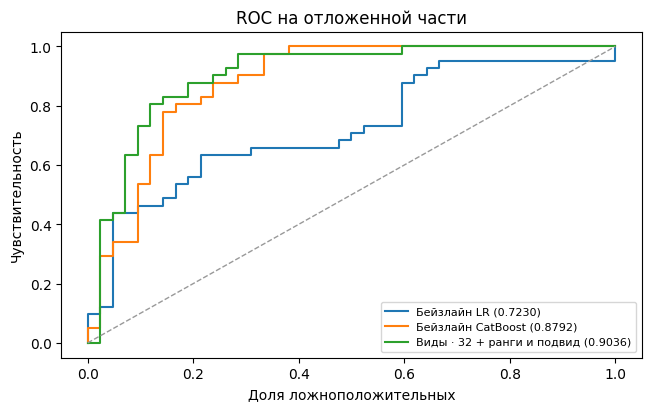

In [8]:
with threadpool_limits(limits=1):
    hold_models = [Fitted(by_name[name], dev) for name in selected]
    pred = np.mean([m.predict(bank, hold) for m in hold_models], axis=0)
    hold_baseline = {name:Fitted(by_name[name], dev).predict(bank, hold) for name in (BASE,BASE_CB)}

target = y[hold]
hold_auc = roc_auc_score(target, pred)
rng = np.random.default_rng(SEED)
by_class = [np.flatnonzero(target == j) for j in (0,1)]
boot = np.concatenate([rng.choice(idx, size=(1500,len(idx)), replace=True) for idx in by_class], axis=1)
auc_ci = np.quantile([roc_auc_score(target[b], pred[b]) for b in boot], [.025,.975])
auc_base = roc_auc_score(target, hold_baseline[BASE])
diff_ci = np.quantile([
    roc_auc_score(target[b], pred[b]) - roc_auc_score(target[b], hold_baseline[BASE][b])
    for b in boot
], [.025,.975])
binary_auc = balanced_accuracy_score(target, pred >= limit)
print(f"Holdout AUC {hold_auc:.4f}, 95% ДИ [{auc_ci[0]:.4f}, {auc_ci[1]:.4f}].")
print(f"Бейзлайн LR {auc_base:.4f}, CatBoost {roc_auc_score(target,hold_baseline[BASE_CB]):.4f}.")
print(f"Разница с LR {hold_auc-auc_base:+.4f}, парный 95% ДИ [{diff_ci[0]:+.4f}, {diff_ci[1]:+.4f}].")
print(f"AUC бинарной метки при фиксированном пороге {binary_auc:.4f}.")
display(pd.DataFrame([
    {"Когорта": c, "N": sum(cohort[hold] == c), "Holdout AUC": roc_auc_score(target[m], pred[m]),
     "Бейзлайн LR": roc_auc_score(target[m], hold_baseline[BASE][m])}
    for c in np.unique(cohort[hold]) for m in [cohort[hold] == c] if np.unique(target[m]).size == 2
]).round(4))

threshold_holdout_rows = []
for label, names in finalists.items():
    scores = pred if label == selected_label else None
    if scores is None:
        with threadpool_limits(limits=1):
            scores = np.mean([Fitted(by_name[name], dev).predict(bank, hold) for name in names], axis=0)
    threshold = youden_threshold(y[dev], combine_oof(names, 0)[dev])
    hard = scores >= threshold
    hard_auc = roc_auc_score(target, hard)
    assert np.isclose(hard_auc, balanced_accuracy_score(target, hard))
    hard_ci = np.quantile([roc_auc_score(target[b], hard[b]) for b in boot], [.025, .975])
    threshold_holdout_rows.append({
        "Модель": label, "N": len(hold), "ROC AUC оценок": roc_auc_score(target, scores),
        "ROC AUC 0/1": hard_auc, "ДИ 0/1 нижний": hard_ci[0], "ДИ 0/1 верхний": hard_ci[1],
        "Порог": threshold,
    })
holdout_comparison = pd.DataFrame(threshold_holdout_rows).set_index("Модель")
display(holdout_comparison.round(4))
print(f"Диагностика порога для {selected_label}. ROC AUC 0/1: "
      f"CV {threshold_summary.loc[(selected_label,'CV'),'ROC AUC 0/1']:.4f}, "
      f"LOCO {threshold_summary.loc[(selected_label,'LOCO'),'ROC AUC 0/1']:.4f}, "
      f"holdout {holdout_comparison.loc[selected_label,'ROC AUC 0/1']:.4f}.")

fig, ax = plt.subplots(figsize=(6.4,4), layout="constrained")
for name, p in [*hold_baseline.items(), (selected_label, pred)]:
    x, z, _ = roc_curve(target, p)
    ax.plot(x, z, label=f"{name} ({roc_auc_score(target,p):.4f})")
ax.plot([0,1],[0,1], "--", color="#999999", linewidth=1)
ax.set(xlabel="Доля ложноположительных", ylabel="Чувствительность",
       title="ROC на отложенной части")
ax.legend(loc="lower right", fontsize=8)
plt.show()

In [9]:
def feature_importance(model):
    if model.scaler is not None:
        signed = model.model.coef_[0]
        return pd.Series(signed, index=model.columns)
    if model.spec.model == "lgbm":
        gain = model.model.booster_.feature_importance(importance_type="gain")
        return pd.Series(gain, index=model.columns)
    return pd.Series(model.model.get_feature_importance(), index=model.columns)

for name, model in zip(selected, hold_models):
    local = feature_importance(model)
    top = local.abs().nlargest(14).index
    fold_models = results[name][0][2]
    loo_models = results[name][1][2]
    stable = pd.concat([feature_importance(m) for m in fold_models], axis=1).reindex(top)
    cross_cohort = pd.concat([feature_importance(m) for m in loo_models], axis=1).reindex(top)
    summary = pd.DataFrame({
        "Вклад на разработке": local[top],
        "Выбран из 5 CV": stable.notna().sum(axis=1),
        "Выбран из 5 LOCO": cross_cohort.notna().sum(axis=1),
    })
    if model.scaler is not None:
        summary["Знак совпал в CV"] = np.sign(stable).eq(np.sign(local[top]), axis=0).sum(axis=1)
    display(Markdown(f"**{name}.** " + ("Коэффициенты на 1 стандартное отклонение."
        if model.scaler is not None else "Важность бустинга без знака. Направление маркеров показано ниже.")))
    display(summary.round(3))

literature_rows = []
for taxon in ORAL + GUT:
    col = "Вид · " + taxon
    if col not in bank["species"]:
        continue
    s = bank["species"][col].to_numpy()
    diffs = [s[dev][(cohort[dev]==g)&(y[dev]==1)].mean() -
             s[dev][(cohort[dev]==g)&(y[dev]==0)].mean() for g in np.unique(cohort)]
    literature_rows.append({"Вид": taxon, "Доля обнаружения КРР": (s[dev][y[dev]==1]>0).mean(),
        "Доля обнаружения контроля": (s[dev][y[dev]==0]>0).mean(),
        "Когорт с большей средней долей при КРР": int((np.asarray(diffs)>0).sum())})
display(pd.DataFrame(literature_rows).set_index("Вид").round(3))

**Виды · 32 + ранги и подвид.** Коэффициенты на 1 стандартное отклонение.

,Вклад на разработке,Выбран из 5 CV,Выбран из 5 LOCO,Знак совпал в CV
Средний ранг обнаруженных оральных,0.546,5,5,5
Вид · Fusobacterium nucleatum,0.436,5,5,5
Вид · Parvimonas micra,0.363,5,5,5
Вид · Gemella morbillorum,0.362,5,5,5
unknown Firmicutes [meta_mOTU_v2_6091],0.335,3,2,3
unknown Clostridiales [meta_mOTU_v2_6105],0.316,5,5,5
unknown Dialister [meta_mOTU_v2_5867],0.294,5,5,5
Контраст процентилей оральные / кишечные,0.283,5,5,5
Вид · Solobacterium moorei,0.271,5,5,5
unknown Peptostreptococcaceae [meta_mOTU_v2_7331],-0.242,5,5,5


,Доля обнаружения КРР,Доля обнаружения контроля,Когорт с большей средней долей при КРР
Вид,,,
Fusobacterium nucleatum,0.451,0.077,5
Parvimonas micra,0.604,0.214,5
Peptostreptococcus stomatis,0.451,0.161,5
Gemella morbillorum,0.555,0.220,5
Solobacterium moorei,0.451,0.143,5
Peptostreptococcus anaerobius,0.152,0.042,5
Porphyromonas asaccharolytica,0.213,0.048,5
Porphyromonas somerae,0.146,0.018,5
Porphyromonas uenonis,0.220,0.024,5


In [10]:
comparison = [
    ("Размер панели", "Виды · 8", "Виды · 32"),
    ("Вид против mOTU при равном бюджете", "Виды · 32", "mOTU · 32"),
    ("Род против вида", "Роды · 32", "Виды · 32"),
    ("Частичная агрегация семейств", "Семейства и остаток · 32", "Роды · 32"),
    ("Фиксированные маркеры", "Виды · 16 + панель", "Виды · 16"),
    ("Баланс", "Виды · 16 + баланс", "Виды · 16"),
    ("Ранги и подвид в LR", "Виды · 32 + ранги и подвид", "Виды · 32"),
    ("Ранги и подвид в LightGBM", "LightGBM · виды · 32 + ранги", "LightGBM · виды · 32"),
    ("Баланс в LightGBM", "LightGBM · виды · 32 + баланс", "LightGBM · виды · 32"),
    ("Разнообразие", "Виды · 16 + экология", "Виды · 16"),
    ("Метаданные", "Виды · 16 + метаданные", "Виды · 16"),
]
metrics = ["CV средняя", "LOCO средняя"]
delta = pd.DataFrame({title: table.loc[treatment,metrics] - table.loc[control,metrics]
                      for title,treatment,control in comparison}).T
display(delta.rename(columns=lambda c:"Δ "+c).round(4))
winner_metrics = mix_row if accept_mix else table.loc[chosen]
display(Markdown(
    f"**Итог.** {selected_label}, медианное число входов {winner_metrics['Признаков']:.0f}. "
    f"CV **{winner_metrics['CV средняя']:.4f}** против **{table.loc[BASE,'CV средняя']:.4f}** "
    f"у LR-бейзлайна. LOCO **{winner_metrics['LOCO средняя']:.4f}** против "
    f"**{table.loc[BASE,'LOCO средняя']:.4f}**. Holdout **{hold_auc:.4f}**. "
    f"Возраст и технические ковариаты проверены отдельной моделью "
    f"(CV {table.loc['Только метаданные','CV средняя']:.4f}), когорта отдельно "
    f"(CV {table.loc['Только когорта','CV средняя']:.4f})."
))

,Δ CV средняя,Δ LOCO средняя
Размер панели,-0.0180,-0.0838
Вид против mOTU при равном бюджете,0.0056,0.0135
Род против вида,-0.0029,-0.0051
Частичная агрегация семейств,-0.0208,-0.0021
Фиксированные маркеры,0.0112,0.0207
Баланс,0.0083,0.0201
Ранги и подвид в LR,0.0042,0.0074
Ранги и подвид в LightGBM,-0.0043,0.0242
Баланс в LightGBM,-0.0057,0.0160
Разнообразие,0.0060,0.0118


**Итог.** Виды · 32 + ранги и подвид, медианное число входов 38. CV **0.8640** против **0.6890** у LR-бейзлайна. LOCO **0.8495** против **0.6724**. Holdout **0.9036**. Возраст и технические ковариаты проверены отдельной моделью (CV 0.6127), когорта отдельно (CV 0.5486).

Графики и знаки коэффициентов описывают ассоциации. Известный дизайн «случай–контроль», композиционность, глубина и возможное пересечение с опубликованными когортами ограничивают перенос. Даже для *F. prausnitzii* направления могут зависеть от штамма и стадии. Для клинического применения нужны независимые проспективные когорты, анализ аденом и сравнение с FIT. Прежний PDF-шаблон `solution_template.py` отличается от действующего формата площадки и Google Docs. По уточнению пользователя в `submission.csv` столбец `label` содержит непрерывную оценку из `predict_proba`. Последняя ячейка показывает отдельную таблицу с классами 0/1. В прочитанной ранее версии регламента фигурируют бинарные метки. Приём непрерывной выгрузки площадкой не проверен.

## 6. Роды и ансамбль с CatBoost
Проверяем шесть агрегированных оральных родов и смешивание оценок LR с CatBoost на тех же 38 признаках. Результаты относятся к разработочной части. Рейтинг таксонов из заметки, рассчитанный на полном train, не использован для отбора. Эти дополнительные сравнения оставляют основную процедуру выбора модели прежней.

In [11]:
# Дополнительные эксперименты на тех же сгибах разработочной части.
reference = "Виды · 32 + ранги и подвид"
oral_genera = ["Fusobacterium", "Parvimonas", "Peptostreptococcus", "Gemella",
               "Solobacterium", "Porphyromonas"]
genus_panel = bank["genus"][["Род · " + name for name in oral_genera]]
# Каждый признак суммирует mOTU одного рода, включая mOTU без уточнения вида.
bank["oral_genera"] = np.log1p(genus_panel / EPS).add_prefix("Оральная панель · ")
genus_spec = Spec("LR + 6 оральных родов", extra=("signature", "oral_genera"))
cat_spec = Spec("CatBoost · те же 38 признаков", extra=("signature",), model="cb", strength=3)

def extra_trial(spec):
    cv = evaluate(spec, cv_splits)
    loco = evaluate(spec, loco_splits)
    return comparison_row(spec.name, cv[:2], loco[:2], [len(m.columns) for m in cv[2]]), cv, loco

with threadpool_limits(limits=1):
    genus_row, _, _ = extra_trial(genus_spec)
    cat_row, cat_cv, cat_loco = extra_trial(cat_spec)

ref_cv, ref_loco = results[reference]
extra_rows = [table.loc[reference].to_dict() | {"Модель": reference}, genus_row, cat_row]
for cat_weight in (.15, .30, .50):
    cv_scores = (1-cat_weight)*ref_cv[1] + cat_weight*cat_cv[1]
    loco_scores = (1-cat_weight)*ref_loco[1] + cat_weight*cat_loco[1]
    extra_rows.append(comparison_row(
        f"LR + CatBoost ({cat_weight:.0%} CatBoost)",
        (aucs_from_oof(cv_scores, cv_splits), cv_scores),
        (aucs_from_oof(loco_scores, loco_splits), loco_scores),
        [len(set(l.columns) | set(c.columns)) for l,c in zip(ref_cv[2], cat_cv[2])],
    ))
extra_comparison = pd.DataFrame(extra_rows).set_index("Модель")
display(extra_comparison[["CV средняя", "LOCO средняя", "LOCO минимум", "Признаков"]].round(4))


,CV средняя,LOCO средняя,LOCO минимум,Признаков
Модель,,,,
Виды · 32 + ранги и подвид,0.8640,0.8495,0.7836,38.0
LR + 6 оральных родов,0.8727,0.8552,0.7926,44.0
CatBoost · те же 38 признаков,0.8526,0.8151,0.7487,38.0
LR + CatBoost (15% CatBoost),0.8647,0.8460,0.7774,38.0
LR + CatBoost (30% CatBoost),0.8670,0.8457,0.7774,38.0
LR + CatBoost (50% CatBoost),0.8647,0.8390,0.7744,38.0


In [12]:
# Финальное обучение на всех размеченных строках с выбранной конфигурацией.
with threadpool_limits(limits=1):
    final_models = [Fitted(by_name[name], np.arange(len(train))) for name in selected]

def predict_submission(test_df):
    assert set(test_df.columns) == required - {"label"}
    ids = test_df["sample_id"]
    assert ids.notna().all() and ids.is_unique and not ids.isin(train["sample_id"]).any()
    if test_df.empty:
        return pd.DataFrame({"sample_id": ids, "label": pd.Series([], dtype=float)})
    blocks = make_features(test_df)
    scores = np.mean([m.predict(blocks, np.arange(len(test_df))) for m in final_models], axis=0)
    assert np.isfinite(scores).all() and ((0 <= scores) & (scores <= 1)).all()
    return pd.DataFrame({"sample_id": ids.to_numpy(), "label": scores})


In [13]:
test = pd.read_csv(TEST_PATH, dtype={"sample_id": str})
submission = predict_submission(test)
assert submission.columns.tolist() == ["sample_id", "label"]
assert submission["sample_id"].tolist() == test["sample_id"].tolist()
assert len(submission) == len(test)
probe = test.iloc[::3, ::-1]
pd.testing.assert_frame_equal(predict_submission(probe), submission.iloc[::3].reset_index(drop=True))

submission_path = Path(os.environ.get("GUT_SUBMISSION", "submission.csv"))
if submission_path.resolve() in {TRAIN_PATH.resolve(), TEST_PATH.resolve()}:
    raise ValueError("Путь для submission совпадает с одним из входных CSV")
submission.to_csv(submission_path, index=False, lineterminator="\n")
labels = submission.assign(label=submission["label"].ge(limit).astype(int))
with pd.option_context("display.max_rows", None):
    display(labels)


,sample_id,label
0,S0125,1
1,S0242,0
2,S0053,0
3,S0173,0
4,S0453,1
5,S0342,1
6,S0438,0
7,S0222,0
8,S0429,0
9,S0134,0
